# Don't Miss the Battery: E3 zero-shot detection (no training on RecyBat24)
**Group 3 (Bhavyasree Kondi, Bhoomika Lnu, Sanjana Reddy Katham, Sharan Somshekhar Patil), DATA-255**

Can an open-vocabulary detector find batteries from a text prompt alone, with no RecyBat24 training? This
matters for recycling plants that meet new battery shapes the trained model has never seen. Three zero-shot
detectors are tested on the **same test set** with the **same safety evaluation** as the trained models:

| Model | Type | Weights |
|---|---|---|
| OWLv2 (base, patch 16, ensemble) | CLIP-based open-vocabulary detector | `google/owlv2-base-patch16-ensemble` |
| Grounding DINO (tiny) | DINO detector grounded on text | `IDEA-Research/grounding-dino-tiny` |
| YOLO-World v2 (s) | real-time open-vocabulary YOLO | `yolov8s-worldv2.pt` (Ultralytics) |

Three prompt styles: **names** ("pouch battery"), **descriptive** ("a flat soft pouch lithium-ion battery"),
and **generic** (one prompt, "battery", type not asked). The detectors never see RecyBat24 labels, except that
the operating threshold is picked on the validation set, exactly as for the trained models.

**Before running:** Runtime > Change runtime type > T4 GPU, then Runtime > Run all (~40 min).
Each finished model + prompt style is saved to Drive, so after a disconnect, Run all again and it continues.

In [1]:
!pip -q install ultralytics==8.4.216 transformers==5.24.0 "git+https://github.com/ultralytics/CLIP.git"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# ---- Config ----
SEED = 42
IMG_SIZE = 640
IOU_MATCH = 0.5
TARGET_PRECISION = 0.90
MISS_COST = 10
COST_RATIOS = list(range(1, 21))
N_BOOT = 1000
PROMPTS = {   # one prompt per class, in class order: cylindric, pouch, prismatic
    "names":       ["cylindrical battery", "pouch battery", "prismatic battery"],
    "descriptive": ["a cylindrical lithium-ion battery cell", "a flat soft pouch lithium-ion battery",
                    "a rectangular hard-case prismatic lithium-ion battery"],
    "generic":     ["battery"],
}
ZS_MODELS = ["owlv2", "grounding_dino", "yolo_world"]
DATA_URL = "https://zenodo.org/api/records/15490523/files/recybat24.tar.gz/content"
ROOT = "/content/recybat24"

import os, json, random, time, glob, re, tarfile, math, contextlib, io, urllib.request, shutil
from collections import defaultdict, Counter
import numpy as np
import torch, torchvision
import matplotlib.pyplot as plt
import cv2

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE_ARG = 0 if dev.type == "cuda" else "cpu"
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device", dev)
if dev.type == "cuda":
    print(torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU")

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device cuda
Tesla T4


In [3]:
# ---- Folders: split and trained-model results from Drive, outputs to E3_zero_shot ----
if os.path.isdir("/kaggle/working"):   # Kaggle: outputs in /kaggle/working are kept
    BASE = "/kaggle/working"
else:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE = "/content/drive/MyDrive/dont_miss_the_battery"
    except ImportError:
        BASE = "./outputs"
E2_DIR = os.path.join(BASE, "E2_safety")
E1_DIR = os.path.join(BASE, "E1_detectors")
OUT = os.path.abspath(os.path.join(BASE, "E3_zero_shot"))
# Without Drive, take the saved split and the trained-model summary from the project's GitHub repo
REPO_RAW = "https://raw.githubusercontent.com/bhoomikaa/dont-miss-the-battery/main/results"
for d, f in [(E2_DIR, "E2/split.json"), (E1_DIR, "E1/E1_summary.json")]:
    if not os.path.exists(os.path.join(d, os.path.basename(f))):
        os.makedirs(d, exist_ok=True)
        urllib.request.urlretrieve(f"{REPO_RAW}/{f}", os.path.join(d, os.path.basename(f)))
        print("Fetched", f, "from GitHub")
assert os.path.exists(os.path.join(E2_DIR, "split.json")), "Run the E2 notebook first (it saves the split)."
os.makedirs(OUT, exist_ok=True)
FIG = os.path.join(OUT, "figures"); os.makedirs(FIG, exist_ok=True)
print("Outputs ->", OUT)

Fetched E2/split.json from GitHub
Fetched E1/E1_summary.json from GitHub
Outputs -> /kaggle/working/E3_zero_shot


In [4]:
# ---- Download + extract RecyBat24 (Zenodo record 15490523, CC BY-NC-ND 4.0) ----
if not os.path.exists(os.path.join(ROOT, ".done")):
    os.makedirs(ROOT, exist_ok=True)
    tgz = "/content/recybat24.tar.gz"
    if not os.path.exists(tgz):
        print("Downloading ~263 MB ...")
        urllib.request.urlretrieve(DATA_URL, tgz)
    with tarfile.open(tgz) as t:
        try:
            t.extractall(ROOT, filter="data")
        except TypeError:
            t.extractall(ROOT)
    open(os.path.join(ROOT, ".done"), "w").close()

# ---- Detection annotations (the instance-segmentation file repeats every battery 3x, so skip it) ----
coco_files = {}
for p in glob.glob(ROOT + "/**/*.json", recursive=True):
    low = p.lower()
    if "segmentation" in os.path.basename(low):
        continue
    try:
        d = json.load(open(p))
    except Exception:
        continue
    if isinstance(d, dict) and {"images", "annotations", "categories"} <= d.keys():
        if "train" in low:
            coco_files["train"] = p
        elif "val" in low:
            coco_files["val"] = p
assert {"train", "val"} <= coco_files.keys(), coco_files
coco = {k: json.load(open(v)) for k, v in coco_files.items()}
for k, d in coco.items():
    print(k, "| images:", len(d["images"]), "| boxes:", len(d["annotations"]))

img_index = defaultdict(list)
for p in glob.glob(ROOT + "/**/*", recursive=True):
    if p.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
        img_index[os.path.basename(p)].append(p)

def resolve(file_name, split):
    direct = os.path.join(os.path.dirname(coco_files[split]), file_name)
    if os.path.exists(direct):
        return direct
    cands = img_index.get(os.path.basename(file_name), [])
    for c in cands:
        if split in c.lower():
            return c
    if cands:
        return cands[0]
    raise FileNotFoundError(file_name)

used = sorted({a["category_id"] for s in coco.values() for a in s["annotations"]})
cat_names = {c["id"]: c["name"] for c in coco["train"]["categories"]}
cat2label = {cid: i + 1 for i, cid in enumerate(used)}            # 1..K (0 = background)
CLASSES = ["__background__"] + [cat_names.get(cid, str(cid)) for cid in used]
K = len(CLASSES) - 1
print("Classes:", CLASSES[1:])

train | images: 1421 | boxes: 1437
val | images: 1407 | boxes: 1434
Classes: ['cylindric', 'pouch', 'prismatic']


In [5]:
# ---- Leak-free split (identical to the Faster R-CNN notebooks): released val -> val + test by battery ----
GROUP_REGEX = r"^(\d+)_\d+_(?:[A-Za-z]_)?\d+_([A-Za-z]+)"

def battery_id(fname):
    stem = os.path.splitext(os.path.basename(fname))[0]
    m = re.search(GROUP_REGEX, stem)
    return "_".join(m.groups()) if m else stem

from sklearn.model_selection import StratifiedGroupKFold
val_imgs = coco["val"]["images"]
groups = [battery_id(i["file_name"]) for i in val_imgs]
types = [g.rsplit("_", 1)[-1] for g in groups]
vi, ti = next(StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED).split(val_imgs, types, groups=groups))
val_ids = [val_imgs[i]["id"] for i in vi]
test_ids = [val_imgs[i]["id"] for i in ti]
split_e2 = os.path.join(E2_DIR, "split.json")
s = json.load(open(split_e2)); val_ids, test_ids = s["val_ids"], s["test_ids"]   # exact images of the E1/E2 runs
print("Loaded the E2 (Faster R-CNN) split from Drive")
bat_of = {i["id"]: battery_id(i["file_name"]) for i in val_imgs}
vb, tb = {bat_of[i] for i in val_ids}, {bat_of[i] for i in test_ids}
assert not (vb & tb) and len(val_ids) + len(test_ids) == len(val_imgs)
print(f"val {len(val_ids)} imgs / {len(vb)} batteries | test {len(test_ids)} imgs / {len(tb)} batteries")
json.dump({"val_ids": val_ids, "test_ids": test_ids, "seed": SEED}, open(os.path.join(OUT, "split.json"), "w"))

Loaded the E2 (Faster R-CNN) split from Drive
val 702 imgs / 47 batteries | test 705 imgs / 47 batteries


In [6]:
# ---- Ground truth access (same class as the Faster R-CNN notebooks, used for evaluation) ----
class BatteryDet:
    def __init__(self, split, img_ids=None):
        d = coco[split]
        self.split = split
        self.imgs = {i["id"]: i for i in d["images"]}
        self.ids = list(img_ids) if img_ids is not None else list(self.imgs)
        self.anns = defaultdict(list)
        for a in d["annotations"]:
            self.anns[a["image_id"]].append(a)

    def __len__(self):
        return len(self.ids)

    def gt(self, iid):
        boxes, labels = [], []
        for a in self.anns[iid]:
            x, y, w, h = a["bbox"]
            if w >= 1 and h >= 1:
                boxes.append([x, y, x + w, y + h]); labels.append(cat2label[a["category_id"]])
        return np.array(boxes, np.float32).reshape(-1, 4), np.array(labels, np.int64)

    def battery(self, iid):
        return battery_id(self.imgs[iid]["file_name"])

    def path(self, iid):
        return resolve(self.imgs[iid]["file_name"], self.split)

train_ds = BatteryDet("train")
val_ds = BatteryDet("val", val_ids)
test_ds = BatteryDet("val", test_ids)
print(len(train_ds), len(val_ds), len(test_ds))

1421 702 705


In [7]:
# ---- COCO metrics (identical to the Faster R-CNN notebooks) ----
from torchvision.ops import box_iou, nms
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

def make_gt(ds):
    images, anns = [], []
    for iid in ds.ids:
        info = ds.imgs[iid]
        images.append({"id": iid, "width": info.get("width", IMG_SIZE), "height": info.get("height", IMG_SIZE)})
        b, l = ds.gt(iid)
        for bb, ll in zip(b, l):
            w, h = float(bb[2] - bb[0]), float(bb[3] - bb[1])
            anns.append({"id": len(anns) + 1, "image_id": iid, "category_id": int(ll),
                         "bbox": [float(bb[0]), float(bb[1]), w, h], "area": w * h, "iscrowd": 0})
    c = COCO()
    c.dataset = {"images": images, "annotations": anns,
                 "categories": [{"id": i, "name": n} for i, n in enumerate(CLASSES) if i > 0]}
    with contextlib.redirect_stdout(io.StringIO()):
        c.createIndex()
    return c

def coco_metrics(preds, gt):
    res = [{"image_id": iid, "category_id": int(l), "score": float(s),
            "bbox": [float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])]}
           for iid, p in preds.items() for b, s, l in zip(p["boxes"], p["scores"], p["labels"])]
    if not res:
        return {"mAP50_95": 0.0, "mAP50": 0.0, "mAP75": 0.0, "per_class": {}}
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(gt, gt.loadRes(res), "bbox"); E.evaluate(); E.accumulate(); E.summarize()
    prec = E.eval["precision"]
    ap = lambda p: float(p[p > -1].mean()) if (p > -1).any() else float("nan")
    per_class = {CLASSES[k + 1]: {"AP50_95": ap(prec[:, :, k, 0, -1]), "AP50": ap(prec[0, :, k, 0, -1])} for k in range(K)}
    return {"mAP50_95": float(E.stats[0]), "mAP50": float(E.stats[1]), "mAP75": float(E.stats[2]), "per_class": per_class}

In [8]:
# ---- Safety evaluation (identical to the Faster R-CNN notebooks) ----
THS = np.round(np.arange(0.01, 1.0, 0.01), 2)

def match(preds, ds, class_aware):
    G = {"score": [], "cls": [], "pred": [], "bat": []}
    FA = {"score": [], "label": [], "bat": []}
    for iid in ds.ids:
        gb, gl = ds.gt(iid); bat = ds.battery(iid)
        p = preds[iid]; pb, ps, pl = torch.from_numpy(p["boxes"]), torch.from_numpy(p["scores"]), p["labels"]
        if not class_aware and len(pb):
            keep = nms(pb, ps, 0.5); pb, ps, pl = pb[keep], ps[keep], pl[keep.numpy()]
        ious = box_iou(pb, torch.from_numpy(gb)).numpy() if len(gb) and len(pb) else np.zeros((len(pb), len(gb)))
        g_score = np.full(len(gb), -1.0); g_pred = np.zeros(len(gb), int)
        for j in torch.argsort(ps, descending=True).numpy():
            cand = ious[j].copy(); cand[g_score >= 0] = -1
            if class_aware:
                cand[gl != pl[j]] = -1
            k = int(cand.argmax()) if len(gb) else -1
            if k >= 0 and cand[k] >= IOU_MATCH:
                g_score[k] = float(ps[j]); g_pred[k] = int(pl[j])
            else:
                FA["score"].append(float(ps[j])); FA["label"].append(int(pl[j])); FA["bat"].append(bat)
        G["score"] += g_score.tolist(); G["cls"] += gl.tolist(); G["pred"] += g_pred.tolist(); G["bat"] += [bat] * len(gb)
    return {k: np.array(v) for k, v in G.items()}, {k: np.array(v) for k, v in FA.items()}

def counts(G, FA, t):
    tp = int((G["score"] >= t).sum()); fp = int((FA["score"] >= t).sum()); n = len(G["score"])
    fn = n - tp
    prec = tp / max(tp + fp, 1); rec = tp / max(n, 1)
    return {"thr": float(t), "tp": tp, "fp": fp, "fn": fn, "n": n, "precision": prec, "recall": rec,
            "f1": 2 * prec * rec / max(prec + rec, 1e-9), "miss_rate": fn / max(n, 1)}

def pick_threshold_precision(G, FA):
    rows = [counts(G, FA, t) for t in THS]
    ok = [r for r in rows if r["precision"] >= TARGET_PRECISION]
    best = min(ok, key=lambda r: (r["miss_rate"], -r["precision"])) if ok else max(rows, key=lambda r: r["precision"])
    return best["thr"]

def pick_threshold_cost(G, FA, c):
    return min(THS, key=lambda t: (lambda r: c * r["fn"] + r["fp"])(counts(G, FA, t)))

def bootstrap_miss(G, FA, t, seed=SEED):
    bats = np.unique(G["bat"])
    per = {b: (int(((G["bat"] == b) & (G["score"] >= t)).sum()), int((G["bat"] == b).sum()),
               int(((FA["bat"] == b) & (FA["score"] >= t)).sum())) for b in bats}
    rng = np.random.default_rng(seed); miss, prec = [], []
    for _ in range(N_BOOT):
        s = rng.choice(bats, len(bats), replace=True)
        tp = sum(per[b][0] for b in s); n = sum(per[b][1] for b in s); fp = sum(per[b][2] for b in s)
        miss.append(1 - tp / max(n, 1)); prec.append(tp / max(tp + fp, 1))
    out = {"miss_ci": [float(np.percentile(miss, 2.5)), float(np.percentile(miss, 97.5))],
           "precision_ci": [float(np.percentile(prec, 2.5)), float(np.percentile(prec, 97.5))],
           "n_batteries": int(len(bats))}
    if counts(G, FA, t)["fn"] == 0:
        out["miss_upper95_zero_events"] = float(1 - 0.05 ** (1 / len(bats)))
    return out

def ece(G, FA, min_score=0.05, bins=10):
    s = np.concatenate([G["score"][G["score"] >= min_score], FA["score"][FA["score"] >= min_score]])
    y = np.concatenate([np.ones((G["score"] >= min_score).sum()), np.zeros((FA["score"] >= min_score).sum())])
    edges = np.linspace(min_score, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        b = (s >= lo) & ((s < hi) | (hi == 1))
        if b.any():
            e += b.mean() * abs(y[b].mean() - s[b].mean())
    return float(e)

def confusion(G, FA, t):
    cm = np.zeros((K + 1, K + 1), int)
    for sc, c, p in zip(G["score"], G["cls"], G["pred"]):
        cm[c - 1, p - 1 if sc >= t else K] += 1
    for sc, l in zip(FA["score"], FA["label"]):
        if sc >= t:
            cm[K, l - 1] += 1
    return cm

def safety_report(val_preds, test_preds):
    rep = {}
    for mode in ["class_agnostic", "class_aware"]:
        Gv, Fv = match(val_preds, val_ds, mode == "class_aware")
        Gt, Ft = match(test_preds, test_ds, mode == "class_aware")
        t90 = pick_threshold_precision(Gv, Fv)
        r = {"thr_from_val": t90, "test_at_thr": counts(Gt, Ft, t90), **bootstrap_miss(Gt, Ft, t90),
             "cost": {}, "ece": ece(Gt, Ft)}
        for c in COST_RATIOS:
            tc = pick_threshold_cost(Gv, Fv, c); ct = counts(Gt, Ft, tc)
            r["cost"][c] = {"thr_from_val": float(tc), "cwe_per_battery": (c * ct["fn"] + ct["fp"]) / max(ct["n"], 1),
                            "miss_rate": ct["miss_rate"], "precision": ct["precision"], "fp": ct["fp"], "fn": ct["fn"]}
        r["pr_curve_test"] = [counts(Gt, Ft, t) for t in THS]
        if mode == "class_agnostic":
            cm = confusion(Gt, Ft, t90); r["confusion"] = cm.tolist()
            r["per_class_miss"] = {CLASSES[c]: float(((Gt["cls"] == c) & (Gt["score"] < t90)).sum() / max((Gt["cls"] == c).sum(), 1))
                                   for c in range(1, K + 1)}
            pi, po = CLASSES.index("prismatic") if "prismatic" in CLASSES else None, CLASSES.index("pouch") if "pouch" in CLASSES else None
            if pi and po:
                r["prismatic_as_pouch"] = float(cm[pi - 1, po - 1] / max(cm[pi - 1].sum(), 1))
                r["pouch_as_prismatic"] = float(cm[po - 1, pi - 1] / max(cm[po - 1].sum(), 1))
        rep[mode] = r
    return rep

val_gt, test_gt = make_gt(val_ds), make_gt(test_ds)

In [9]:
# ---- Images in memory (BGR uint8) ----
val_imgs_bgr = {iid: cv2.imread(val_ds.path(iid)) for iid in val_ds.ids}
test_imgs_bgr = {iid: cv2.imread(test_ds.path(iid)) for iid in test_ds.ids}
print("images:", len(val_imgs_bgr), "val |", len(test_imgs_bgr), "test")

def finish(boxes, cls_scores, typed, max_det=100, min_score=0.001):
    """boxes (N,4) xyxy pixels, cls_scores (N,C). Per box: best class; class-wise NMS 0.5; top 100. Labels 1..K."""
    boxes = torch.as_tensor(boxes, dtype=torch.float32); cs = torch.as_tensor(cls_scores, dtype=torch.float32)
    score, lab = cs.max(1)
    keep = score >= min_score
    boxes, score, lab = boxes[keep], score[keep], lab[keep]
    boxes[:, 0::2] = boxes[:, 0::2].clamp(0, IMG_SIZE); boxes[:, 1::2] = boxes[:, 1::2].clamp(0, IMG_SIZE)
    if len(boxes):
        k = batched_nms(boxes, score, lab, 0.5)[:max_det]
        boxes, score, lab = boxes[k], score[k], lab[k]
    return {"boxes": boxes.numpy(), "scores": score.numpy(), "labels": (lab + 1).numpy().astype(np.int64) if typed
            else np.ones(len(lab), np.int64)}

def cxcywh_to_xyxy(b, W, H):
    cx, cy, w, h = b.unbind(-1)
    return torch.stack([(cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H], -1)

from torchvision.ops import batched_nms

images: 702 val | 705 test


In [10]:
# ---- The three zero-shot detectors: each returns {style: {image_id: prediction}} for a list of images ----
from transformers import Owlv2Processor, Owlv2ForObjectDetection, AutoProcessor, AutoModelForZeroShotObjectDetection

T_START = {}
def progress(tag, done, total, every=200):
    """Print a progress line every `every` images so a long cell never looks frozen."""
    if tag not in T_START or done < T_START[tag][1]:   # new pass (validation, then test)
        T_START[tag] = [time.time(), done]
    T_START[tag][1] = done
    if done and (done % every < (done - 1) % every + 1 or done == total):
        el = time.time() - T_START[tag][0]
        print(f"  {tag}: {done}/{total} images | {el / 60:.1f} min | ~{el / done * (total - done) / 60:.1f} min left", flush=True)

class OWLv2:
    """OWLv2 scores every query independently (sigmoid per query), so all prompt styles run in one pass."""
    ID = "google/owlv2-base-patch16-ensemble"
    def __init__(self):
        self.proc = Owlv2Processor.from_pretrained(self.ID)
        self.model = Owlv2ForObjectDetection.from_pretrained(self.ID).to(dev).eval()
        self.queries = [q for s in PROMPTS.values() for q in s]
        self.cols, i = {}, 0
        for s, qs in PROMPTS.items():
            self.cols[s] = list(range(i, i + len(qs))); i += len(qs)
    @torch.no_grad()
    def __call__(self, imgs_bgr, ids, bs=4):
        out = {s: {} for s in PROMPTS}
        for i in range(0, len(ids), bs):
            rgb = [im[..., ::-1].copy() for im in imgs_bgr[i:i + bs]]
            inp = self.proc(text=[self.queries] * len(rgb), images=rgb, return_tensors="pt").to(dev)
            with torch.autocast(dev.type, enabled=dev.type == "cuda"):
                o = self.model(**inp)
            sc = o.logits.float().sigmoid().cpu()                     # (B, patches, queries)
            S = max(rgb[0].shape[:2])                                 # boxes are relative to the padded square image
            bx = cxcywh_to_xyxy(o.pred_boxes.float().cpu(), S, S)
            for b, iid in enumerate(ids[i:i + bs]):
                for s in PROMPTS:
                    out[s][iid] = finish(bx[b], sc[b][:, self.cols[s]], typed=s != "generic")
            progress("owlv2", min(i + bs, len(ids)), len(ids))
        return out

class GroundingDINO:
    """Prompt tokens attend to each other, so each style is its own pass. Class score = max over the phrase's tokens."""
    ID = "IDEA-Research/grounding-dino-tiny"
    def __init__(self):
        self.proc = AutoProcessor.from_pretrained(self.ID)
        self.model = AutoModelForZeroShotObjectDetection.from_pretrained(self.ID).to(dev).eval()
        self.text, self.tok = {}, {}
        for s, qs in PROMPTS.items():
            text = ". ".join(q.lower() for q in qs) + "."
            enc = self.proc.tokenizer(text, return_offsets_mapping=True)
            spans, pos = [], 0
            for q in qs:
                a = text.index(q.lower(), pos); spans.append((a, a + len(q))); pos = a + len(q)
            self.tok[s] = [[t for t, (x, y) in enumerate(enc["offset_mapping"]) if y > x and x >= a and y <= b] for a, b in spans]
            assert all(self.tok[s]), (s, self.tok[s])
            self.text[s] = text
    @torch.no_grad()
    def __call__(self, imgs_bgr, ids, bs=4):
        out = {s: {} for s in PROMPTS}
        for s in PROMPTS:
            for i in range(0, len(ids), bs):
                rgb = [im[..., ::-1].copy() for im in imgs_bgr[i:i + bs]]
                inp = self.proc(images=rgb, text=[self.text[s]] * len(rgb), return_tensors="pt").to(dev)
                o = self.model(**inp)
                lg = o.logits.float().sigmoid().cpu()                 # (B, queries, text tokens)
                cls = torch.stack([lg[..., t].max(-1).values for t in self.tok[s]], -1)
                H, W = rgb[0].shape[:2]
                bx = cxcywh_to_xyxy(o.pred_boxes.float().cpu(), W, H)
                for b, iid in enumerate(ids[i:i + bs]):
                    out[s][iid] = finish(bx[b], cls[b], typed=s != "generic")
                progress(f"grounding_dino/{s}", min(i + bs, len(ids)), len(ids))
        return out

class YOLOWorldZS:
    def __init__(self):
        from ultralytics import YOLOWorld
        self.model = YOLOWorld("yolov8s-worldv2.pt")
    def __call__(self, imgs_bgr, ids, bs=16):
        out = {s: {} for s in PROMPTS}
        for s, qs in PROMPTS.items():
            self.model.set_classes(qs)
            for i in range(0, len(ids), bs):
                res = self.model.predict(list(imgs_bgr[i:i + bs]), imgsz=IMG_SIZE, conf=0.001, iou=0.7, max_det=100,
                                         verbose=False, device=DEVICE_ARG)
                for iid, r in zip(ids[i:i + bs], res):
                    lab = r.boxes.cls.cpu().numpy().astype(np.int64) + 1
                    out[s][iid] = {"boxes": r.boxes.xyxy.cpu().numpy().astype(np.float32),
                                   "scores": r.boxes.conf.cpu().numpy().astype(np.float32),
                                   "labels": lab if s != "generic" else np.ones_like(lab)}
        return out

BUILD = {"owlv2": OWLv2, "grounding_dino": GroundingDINO, "yolo_world": YOLOWorldZS}

In [11]:
# ---- Evaluation (same matching, thresholds-from-val and battery bootstrap as the trained models) ----
def coco_agnostic(preds, ds):
    """AP for 'is there a battery here', ignoring type: every box and every prediction becomes one class."""
    gt = make_gt(ds)
    for a in gt.dataset["annotations"]:
        a["category_id"] = 1
    gt.dataset["categories"] = [{"id": 1, "name": "battery"}]
    with contextlib.redirect_stdout(io.StringIO()):
        gt.createIndex()
    res = [{"image_id": iid, "category_id": 1, "score": float(s),
            "bbox": [float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])]}
           for iid, p in preds.items() for b, s in zip(p["boxes"], p["scores"])]
    if not res:
        return {"AP50": 0.0, "AP50_95": 0.0}
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(gt, gt.loadRes(res), "bbox"); E.evaluate(); E.accumulate(); E.summarize()
    return {"AP50": float(E.stats[1]), "AP50_95": float(E.stats[0])}

def evaluate(vp, tp, typed):
    r = {"agnostic_coco": coco_agnostic(tp, test_ds), "typed": typed}
    if typed:
        r["coco"] = coco_metrics(tp, test_gt)
    for mode in (["class_agnostic", "class_aware"] if typed else ["class_agnostic"]):
        Gv, Fv = match(vp, val_ds, mode == "class_aware"); Gt, Ft = match(tp, test_ds, mode == "class_aware")
        t = pick_threshold_precision(Gv, Fv)
        m = {"thr_from_val": float(t), "val_precision_at_thr": counts(Gv, Fv, t)["precision"],
             "target_precision_met_on_val": counts(Gv, Fv, t)["precision"] >= TARGET_PRECISION,
             "test_at_thr": counts(Gt, Ft, t), **bootstrap_miss(Gt, Ft, t),
             "pr_curve_test": [counts(Gt, Ft, x) for x in THS]}
        if mode == "class_agnostic" and typed:
            cm = confusion(Gt, Ft, t); m["confusion"] = cm.tolist()
            pi, po = CLASSES.index("prismatic"), CLASSES.index("pouch")
            m["prismatic_as_pouch"] = float(cm[pi - 1, po - 1] / max(cm[pi - 1].sum(), 1))
        r[mode] = m
    return r

In [12]:
# ---- Run (resumable: one results file per model + prompt style) ----
results = {}
vids, tids = list(val_ds.ids), list(test_ds.ids)
for name in ZS_MODELS:
    paths = {s: os.path.join(OUT, f"results_{name}_{s}.json") for s in PROMPTS}
    if all(os.path.exists(p) for p in paths.values()):
        for s, p in paths.items():
            results[(name, s)] = json.load(open(p))
        print(f"[{name}] already done, loaded results"); continue
    t0 = time.time()
    det = BUILD[name]()
    vp = det([val_imgs_bgr[i] for i in vids], vids)
    tp = det([test_imgs_bgr[i] for i in tids], tids)
    for s in PROMPTS:
        results[(name, s)] = evaluate(vp[s], tp[s], typed=s != "generic")
        json.dump(results[(name, s)], open(paths[s], "w"), default=float)
        r = results[(name, s)]; ag = r["class_agnostic"]
        print(f"[{name:14s} {s:11s}] battery AP50 {r['agnostic_coco']['AP50']:.3f} | any-miss {ag['test_at_thr']['miss_rate']:.3f} "
              f"prec {ag['test_at_thr']['precision']:.3f}" +
              (f" | type mAP50 {r['coco']['mAP50']:.3f} type-miss {r['class_aware']['test_at_thr']['miss_rate']:.3f} "
               f"prec {r['class_aware']['test_at_thr']['precision']:.3f}" if r["typed"] else ""))
    print(f"[{name}] {(time.time() - t0) / 60:.1f} min")
    del det
    if dev.type == "cuda":
        torch.cuda.empty_cache()

preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

... (14 outputs left out)

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

  grounding_dino/names: 200/702 images | 1.1 min | ~2.7 min left
  grounding_dino/names: 400/702 images | 2.2 min | ~1.6 min left
  grounding_dino/names: 600/702 images | 3.3 min | ~0.6 min left
  grounding_dino/names: 702/702 images | 3.8 min | ~0.0 min left
  grounding_dino/descriptive: 200/702 images | 1.1 min | ~2.8 min left
  grounding_dino/descriptive: 400/702 images | 2.2 min | ~1.7 min left
  grounding_dino/descriptive: 600/702 images | 3.4 min | ~0.6 min left
  grounding_dino/descriptive: 702/702 images | 3.9 min | ~0.0 min left
  grounding_dino/generic: 200/702 images | 1.1 min | ~2.7 min left
  grounding_dino/generic: 400/702 images | 2.2 min | ~1.6 min left
  grounding_dino/generic: 600/702 images | 3.3 min | ~0.6 min left
  grounding_dino/generic: 702/702 images | 3.8 min | ~0.0 min left
  grounding_dino/names: 200/705 images | 1.1 min | ~2.7 min left
  grounding_dino/names: 400/705 images | 2.2 min | ~1.7 min left
  grounding_dino/names: 600/705 images | 3.3 min | ~0.6 mi

100%|███████████████████████████████████████| 338M/338M [00:07<00:00, 48.6MiB/s]


[yolo_world     names      ] battery AP50 0.704 | any-miss 0.661 prec 1.000 | type mAP50 0.119 type-miss 0.986 prec 0.041
[yolo_world     descriptive] battery AP50 0.872 | any-miss 0.250 prec 1.000 | type mAP50 0.110 type-miss 1.000 prec 0.000
[yolo_world     generic    ] battery AP50 0.975 | any-miss 0.231 prec 0.989
[yolo_world] 1.5 min


In [13]:
# ---- Summary table: zero-shot vs the trained detectors ----
rows = []
for (name, s), r in results.items():
    ag, aw = r["class_agnostic"], r.get("class_aware")
    rows.append({"model": name, "prompts": s, "battery_AP50": r["agnostic_coco"]["AP50"], "battery_AP50_95": r["agnostic_coco"]["AP50_95"],
                 "any_miss": ag["test_at_thr"]["miss_rate"], "any_miss_CI": ag["miss_ci"], "any_precision": ag["test_at_thr"]["precision"],
                 "any_target_met_on_val": ag["target_precision_met_on_val"],
                 "type_mAP50": r["coco"]["mAP50"] if r["typed"] else None,
                 "type_miss": aw["test_at_thr"]["miss_rate"] if aw else None, "type_miss_CI": aw["miss_ci"] if aw else None,
                 "type_precision": aw["test_at_thr"]["precision"] if aw else None,
                 "type_target_met_on_val": aw["target_precision_met_on_val"] if aw else None,
                 "prism_as_pouch": ag.get("prismatic_as_pouch")})
ref = []
p = os.path.join(E1_DIR, "E1_summary.json")
if os.path.exists(p):
    for r in json.load(open(p)):
        ref.append({"model": r["model"] + " (trained)", "prompts": "-", "type_mAP50": r["mAP50"], "any_miss": r["any_miss@P90"],
                    "type_miss": r["type_miss@P90"], "type_precision": r["type_precision"], "prism_as_pouch": r["prism_as_pouch"]})
json.dump({"zero_shot": rows, "trained_reference": ref}, open(os.path.join(OUT, "E3_summary.json"), "w"), indent=1, default=float)

f = lambda v: "   -  " if v is None else f"{v:6.3f}"
hdr = f"{'model':22s} {'prompts':11s} {'batAP50':>7s} {'anyMiss':>7s} {'anyPrec':>7s} {'typeAP50':>8s} {'typeMiss':>8s} {'typePrec':>8s} {'pr->po':>7s}"
print(hdr); print("-" * len(hdr))
for r in rows + ref:
    print(f"{r['model']:22s} {r['prompts']:11s} {f(r.get('battery_AP50')):>7s} {f(r['any_miss']):>7s} {f(r.get('any_precision')):>7s} "
          f"{f(r['type_mAP50']):>8s} {f(r['type_miss']):>8s} {f(r['type_precision']):>8s} {f(r['prism_as_pouch']):>7s}")
print("\nPrecision target (0.90) reachable on validation?",
      {f"{r['model']}/{r['prompts']}": (r["any_target_met_on_val"], r["type_target_met_on_val"]) for r in rows})

model                  prompts     batAP50 anyMiss anyPrec typeAP50 typeMiss typePrec  pr->po
---------------------------------------------------------------------------------------------
owlv2                  names         0.589   0.660   0.896    0.317    1.000    0.000   0.007
owlv2                  descriptive   0.851   0.489   0.963    0.184    0.997    0.333   0.030
owlv2                  generic       0.357   0.932   0.960      -        -        -       -  
grounding_dino         names         0.998   0.000   0.970    0.376    0.957    0.233   0.000
grounding_dino         descriptive   0.942   0.001   0.953    0.397    0.993    0.417   0.148
grounding_dino         generic       1.000   0.000   0.964      -        -        -       -  
yolo_world             names         0.704   0.661   1.000    0.119    0.986    0.041   0.000
yolo_world             descriptive   0.872   0.250   1.000    0.110    1.000    0.000   0.000
yolo_world             generic       0.975   0.231   0.989  

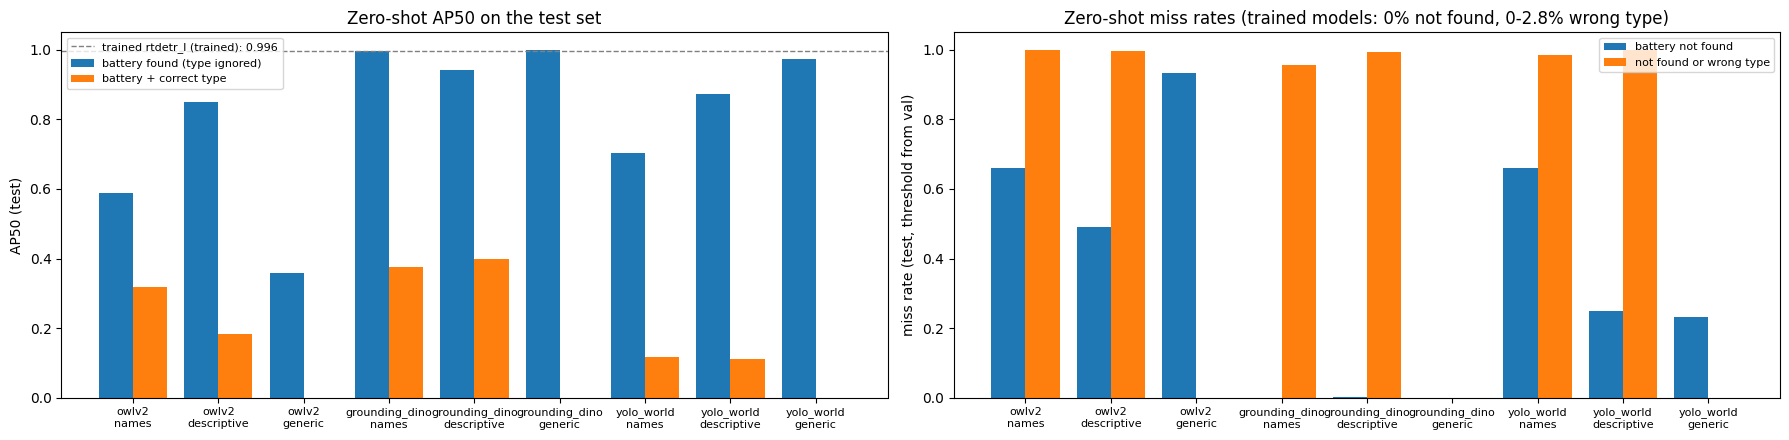

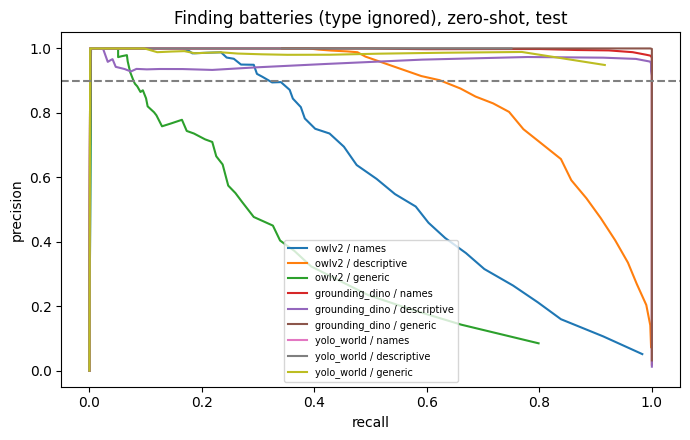

In [14]:
# ---- Figures ----
labels_ = [f"{r['model']}\n{r['prompts']}" for r in rows]
x = np.arange(len(rows))
fig, ax = plt.subplots(1, 2, figsize=(18, 4.5))
ax[0].bar(x - 0.2, [r["battery_AP50"] for r in rows], 0.4, label="battery found (type ignored)")
ax[0].bar(x + 0.2, [r["type_mAP50"] or 0 for r in rows], 0.4, label="battery + correct type")
for r in ref:
    if r["model"].startswith("rtdetr"):
        ax[0].axhline(r["type_mAP50"], ls="--", c="gray", lw=1, label=f"trained {r['model']}: {r['type_mAP50']:.3f}")
ax[0].set_xticks(x); ax[0].set_xticklabels(labels_, fontsize=8); ax[0].set_ylabel("AP50 (test)"); ax[0].legend(fontsize=8)
ax[0].set_title("Zero-shot AP50 on the test set")
ax[1].bar(x - 0.2, [r["any_miss"] for r in rows], 0.4, label="battery not found")
ax[1].bar(x + 0.2, [r["type_miss"] if r["type_miss"] is not None else 0 for r in rows], 0.4, label="not found or wrong type")
ax[1].set_xticks(x); ax[1].set_xticklabels(labels_, fontsize=8); ax[1].set_ylabel("miss rate (test, threshold from val)")
ax[1].legend(fontsize=8); ax[1].set_title("Zero-shot miss rates (trained models: 0% not found, 0-2.8% wrong type)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "E3_zero_shot.png"), dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for (name, s), r in results.items():
    pr = r["class_agnostic"]["pr_curve_test"]
    ax.plot([q["recall"] for q in pr], [q["precision"] for q in pr], label=f"{name} / {s}")
ax.axhline(TARGET_PRECISION, ls="--", c="gray"); ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title("Finding batteries (type ignored), zero-shot, test"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "E3_pr_curves.png"), dpi=120); plt.show()

In [15]:
# ---- Zip results + figures and download ----
pack = os.path.join(BASE, "E3_results") if BASE == "/kaggle/working" else ("/content/E3_results" if os.path.isdir("/content") else "./E3_results")
os.makedirs(pack, exist_ok=True)
for fn in os.listdir(OUT):
    if fn.endswith(".json"):
        shutil.copy(os.path.join(OUT, fn), pack)
shutil.copytree(FIG, os.path.join(pack, "figures"), dirs_exist_ok=True)
zip_path = shutil.make_archive(pack, "zip", pack)
print("Results zip:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    pass

Results zip: /kaggle/working/E3_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>